# Notebook 7 — Final Analysis

This notebook turns the saved experiment outputs into the project's final figures and tables. It **trains nothing**:
it reads the CSVs written by Notebook 6 (`results/temporal_ablation_*.csv`, 10-epoch protocol) and produces

1. the main result: performance versus time-to-event for Model 0 (naive), Model 1 (optical flow) and Model 2 (CNN + LSTM);
2. the proposal's secondary temporal ablation;
3. paired comparisons with confidence intervals (are the differences distinguishable from noise?);
4. the degradation analysis and a check of the proposal's hypothesis;
5. a final results table.

## How to read the numbers

* **Held-out test set.** The 300 official validation videos were never used to select an epoch or tune anything in
  Notebook 6 (epochs were chosen on 20% of the *training* videos). They therefore act as the held-out test set for these
  results and are called the "test set" below. One minor exception: the choice of the *scaled* optical-flow variant
  was made after seeing results on these videos (the two variants differ by about 0.01 AP).
* **Seed mean ± std** (tables, points in Figures 1–2) measures *training* noise over 5 seeds. It understates the real
  uncertainty, which is dominated by the small test set (300 clips).
* **Bootstrap 95% CIs** (Figures 3–4) resample the 300 test clips and compare models on the *same* resamples (paired).
  They are computed on seed-averaged predictions, so their centre can differ slightly from the single-model seed mean.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RESULTS_DIR = Path("./results")
FIGURE_DIR = RESULTS_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

TTE_VALUES = [0.5, 1.0, 1.5]

summary = pd.read_csv(RESULTS_DIR / "temporal_ablation_summary.csv")
bootstrap = pd.read_csv(RESULTS_DIR / "temporal_ablation_bootstrap.csv")
runs = pd.read_csv(RESULTS_DIR / "temporal_ablation_runs.csv")

assert runs["seed"].nunique() >= 5 and set(runs["tte"]) == set(TTE_VALUES)
print("Variants:", list(summary["variant"].unique()))

Variants: ['naive', 'optical_flow', 'last_frame', 'mean_pool', 'lstm_train_shuffled', 'lstm_test_shuffled', 'lstm']


## 1. Plot style

Colours follow the data-viz method: **blue = CNN + LSTM, orange = optical flow** (categorical slots 1 and 2, validated for
colour-blind separation and contrast on the light surface); everything that is a *control* or *reference* is neutral grey.
Every series is also named by a label and a legend, so identity never depends on colour alone. Filled vs hollow
markers carry the "distinguishable from zero" distinction in Figures 3–4.

In [2]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_2 = "#52514e"
GRID = "#e4e3df"
BLUE = "#2a78d6"      # CNN + LSTM
ORANGE = "#eb6834"    # optical flow
NEUTRAL = "#8a8985"   # controls / references

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

DISPLAY = {
    "naive": "Naive", "optical_flow": "Optical flow", "lstm": "CNN + LSTM",
    "last_frame": "Last frame only", "mean_pool": "Mean-pool (no order)",
    "lstm_train_shuffled": "LSTM, shuffled train + test", "lstm_test_shuffled": "LSTM, shuffled at test only",
}
# Names used inside results/temporal_ablation_bootstrap.csv.
BOOT_NAME = {
    "optical_flow": "Optical flow", "last_frame": "Last frame (no temporal)", "mean_pool": "Mean-pool (no order)",
    "lstm_train_shuffled": "LSTM, shuffled train+test", "lstm_test_shuffled": "LSTM, shuffled at test only",
    "lstm": "CNN + LSTM",
}


def stat(variant, tte, column):
    row = summary[(summary["variant"] == variant) & (summary["tte"] == tte)].iloc[0]
    return row[f"{column}_mean"], row[f"{column}_std"]


def boot_row(prefix, name, tte):
    match = bootstrap[(bootstrap["comparison"] == f"{prefix}{name}") & (bootstrap["tte"] == tte)]
    assert len(match) == 1, (prefix, name, tte)
    return match.iloc[0]

## 2. Figure 1 — Main result: performance versus time-to-event

Left: Average Precision (the primary metric). Right: recall at a fixed false-alarm rate (≤10% of normal clips flagged),
the operating-point metric the proposal asks for. Points are 5-seed means with ±1 std (flow and naive are deterministic).
The dotted line is chance.

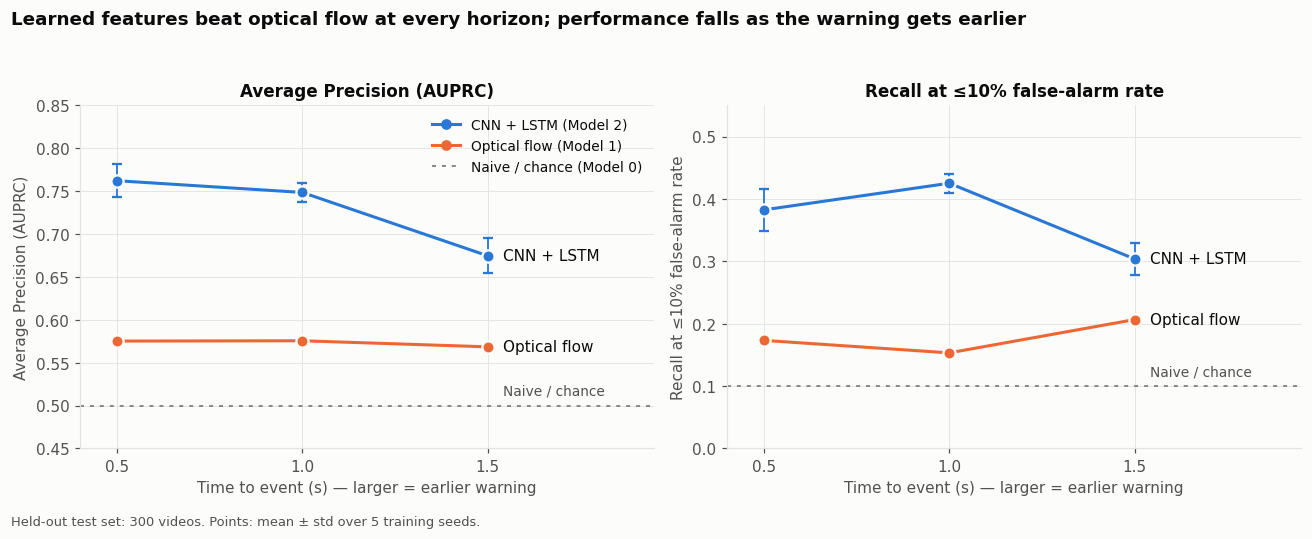

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
panels = [(axes[0], "AP", "Average Precision (AUPRC)", 0.5), (axes[1], "Recall@FPR10", "Recall at ≤10% false-alarm rate", 0.10)]

for ax, metric, ylabel, chance in panels:
    ax.axhline(chance, color=NEUTRAL, linestyle=(0, (2, 3)), linewidth=1.3, zorder=1)
    for variant, colour in [("optical_flow", ORANGE), ("lstm", BLUE)]:
        means = np.array([stat(variant, t, metric)[0] for t in TTE_VALUES])
        stds = np.nan_to_num(np.array([stat(variant, t, metric)[1] for t in TTE_VALUES]))
        ax.errorbar(TTE_VALUES, means, yerr=stds, color=colour, linewidth=2, marker="o", markersize=8,
                    markeredgecolor=SURFACE, markeredgewidth=1.5, capsize=3, elinewidth=1.2, zorder=3,
                    label=DISPLAY[variant])
        ax.annotate(DISPLAY[variant], (TTE_VALUES[-1], means[-1]), xytext=(10, 0), textcoords="offset points",
                    va="center", color=INK, fontsize=10)
    ax.annotate("Naive / chance", (TTE_VALUES[-1], chance), xytext=(10, 5), textcoords="offset points",
                va="bottom", color=INK_2, fontsize=9)
    ax.set_xticks(TTE_VALUES)
    ax.set_xlim(0.4, 1.95)
    ax.set_xlabel("Time to event (s) — larger = earlier warning")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)

axes[0].set_ylim(0.45, 0.85)
axes[1].set_ylim(0.0, 0.55)
handles = [Line2D([], [], color=BLUE, marker="o", linewidth=2, label="CNN + LSTM (Model 2)"),
           Line2D([], [], color=ORANGE, marker="o", linewidth=2, label="Optical flow (Model 1)"),
           Line2D([], [], color=NEUTRAL, linestyle=(0, (2, 3)), linewidth=1.3, label="Naive / chance (Model 0)")]
axes[0].legend(handles=handles, loc="upper right", fontsize=9)
fig.suptitle("Learned features beat optical flow at every horizon; performance falls as the warning gets earlier",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.text(0.01, 0.005, "Held-out test set: 300 videos. Points: mean ± std over 5 training seeds.", fontsize=8.5, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.94))
fig.savefig(FIGURE_DIR / "final_fig1_main_result.png", dpi=170)
plt.show()

## 3. Figure 2 — Temporal ablation

The proposal's secondary experiment: does the learned model genuinely use *temporal* information? Every CNN-based variant
uses the **same frozen ResNet-18 features**; only the temporal handling changes.

* *Last frame only* — one static image, no temporal information at all.
* *Mean-pool* — all 16 frames averaged, order discarded.
* *LSTM shuffled train + test* — LSTM that never sees correct order.
* *LSTM shuffled at test only* — the trained order-aware LSTM, with frames shuffled at test time.

If the LSTM relied on temporal structure, the controls should fall clearly below it.

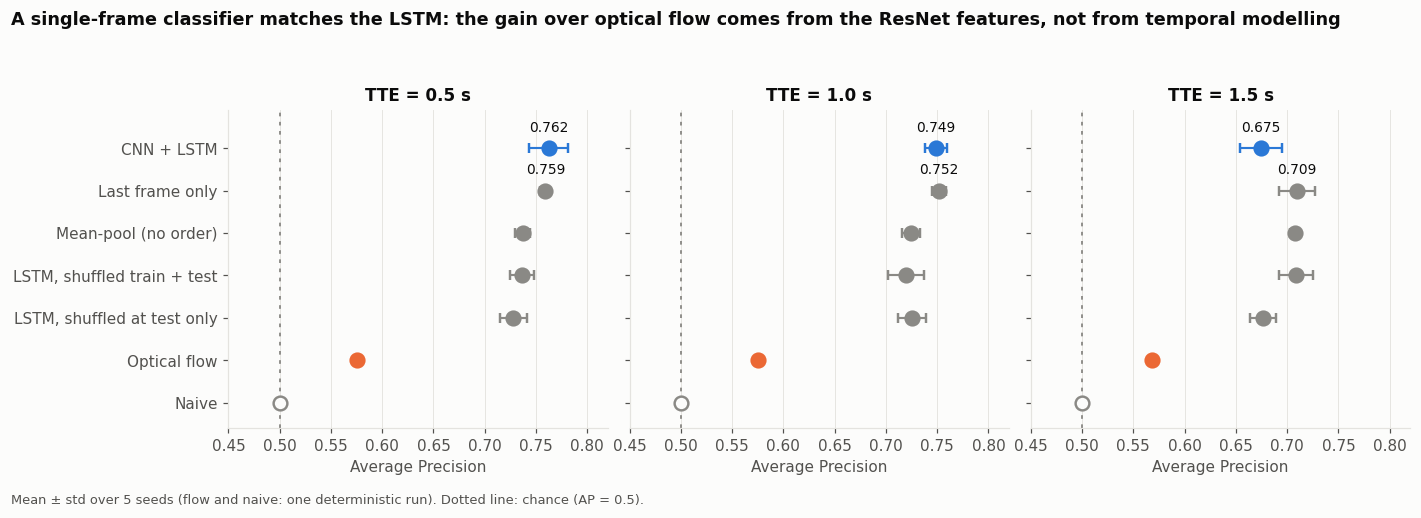

In [4]:
ROW_ORDER = ["lstm", "last_frame", "mean_pool", "lstm_train_shuffled", "lstm_test_shuffled", "optical_flow", "naive"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharex=True, sharey=True)
y_positions = np.arange(len(ROW_ORDER))[::-1]

for ax, tte in zip(axes, TTE_VALUES):
    ax.axvline(0.5, color=NEUTRAL, linestyle=(0, (2, 3)), linewidth=1.2, zorder=1)
    for y, variant in zip(y_positions, ROW_ORDER):
        mean, std = stat(variant, tte, "AP")
        colour = BLUE if variant == "lstm" else ORANGE if variant == "optical_flow" else NEUTRAL
        hollow = variant == "naive"
        ax.errorbar(mean, y, xerr=0 if np.isnan(std) else std, fmt="o", markersize=9,
                    color=colour, markerfacecolor=SURFACE if hollow else colour, markeredgewidth=1.6,
                    capsize=3, elinewidth=1.4, zorder=3)
        if variant in ("lstm", "last_frame"):
            ax.annotate(f"{mean:.3f}", (mean, y), xytext=(0, 11), textcoords="offset points", ha="center",
                        fontsize=9, color=INK)
    ax.set_title(f"TTE = {tte} s")
    ax.set_xlabel("Average Precision")
    ax.set_yticks(y_positions)
    ax.set_yticklabels([DISPLAY[v] for v in ROW_ORDER])
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0.45, 0.82)
    ax.set_ylim(-0.6, len(ROW_ORDER) - 0.1)   # headroom so value labels clear the title

fig.suptitle("A single-frame classifier matches the LSTM: the gain over optical flow comes from the ResNet features, not from temporal modelling",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.text(0.01, 0.005, "Mean ± std over 5 seeds (flow and naive: one deterministic run). Dotted line: chance (AP = 0.5).",
         fontsize=8.5, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.93))
fig.savefig(FIGURE_DIR / "final_fig2_temporal_ablation.png", dpi=170)
plt.show()

## 4. Figure 3 — Is CNN + LSTM really better? Paired comparisons

Each point is the AP difference *CNN + LSTM − other model* on the same resampled test clips, with its 95% bootstrap CI.
**Filled** marker = the interval excludes zero (distinguishable from no difference); **hollow** = it does not.
Right of the dotted zero line favours CNN + LSTM.

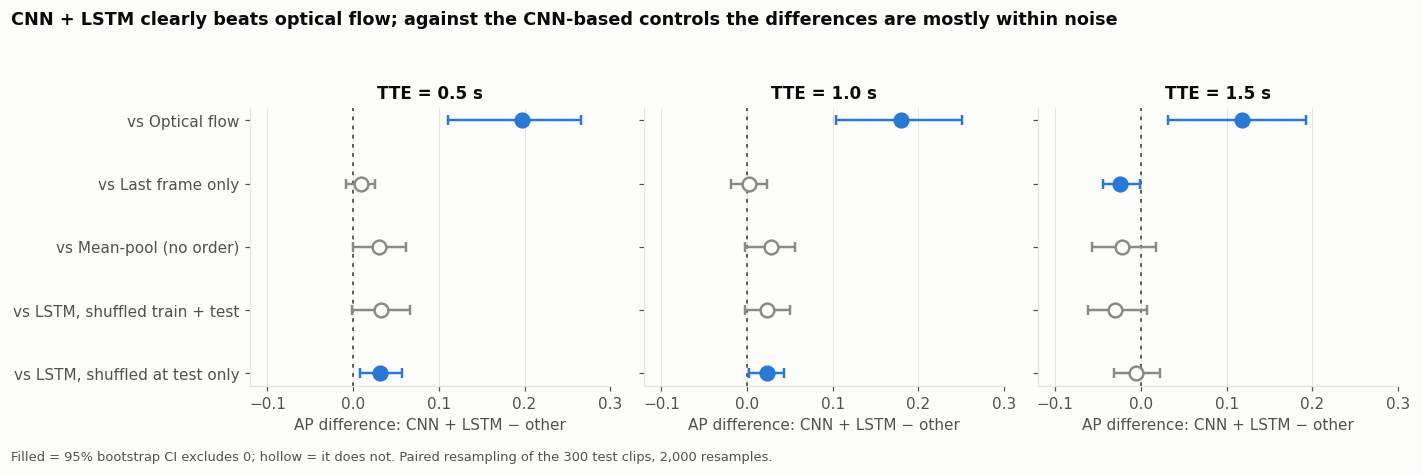

In [5]:
COMPARISONS = ["optical_flow", "last_frame", "mean_pool", "lstm_train_shuffled", "lstm_test_shuffled"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
y_positions = np.arange(len(COMPARISONS))[::-1]

for ax, tte in zip(axes, TTE_VALUES):
    ax.axvline(0, color=INK_2, linestyle=(0, (2, 3)), linewidth=1.2, zorder=1)
    for y, other in zip(y_positions, COMPARISONS):
        row = boot_row("AP diff: CNN+LSTM − ", BOOT_NAME[other], tte)
        colour = BLUE if row["excludes_zero"] else NEUTRAL
        ax.errorbar(row["estimate"], y, xerr=[[row["estimate"] - row["ci_low"]], [row["ci_high"] - row["estimate"]]],
                    fmt="o", markersize=9, color=colour, markerfacecolor=colour if row["excludes_zero"] else SURFACE,
                    markeredgewidth=1.6, capsize=3, elinewidth=1.6, zorder=3)
    ax.set_title(f"TTE = {tte} s")
    ax.set_xlabel("AP difference: CNN + LSTM − other")
    ax.set_yticks(y_positions)
    ax.set_yticklabels([f"vs {DISPLAY[v]}" for v in COMPARISONS])
    ax.grid(axis="y", visible=False)

axes[0].set_xlim(-0.12, 0.30)
fig.suptitle("CNN + LSTM clearly beats optical flow; against the CNN-based controls the differences are mostly within noise",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.text(0.01, 0.005, "Filled = 95% bootstrap CI excludes 0; hollow = it does not. Paired resampling of the 300 test clips, 2,000 resamples.",
         fontsize=8.5, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.93))
fig.savefig(FIGURE_DIR / "final_fig3_paired_differences.png", dpi=170)
plt.show()

## 5. Figure 4 — Degradation with prediction horizon

The proposal's hypothesis was that the learned model degrades **more slowly** than the classical baseline. Each point is the
AP *lost* relative to the 0.5 s horizon (positive = worse at the longer horizon), with a paired bootstrap 95% CI.

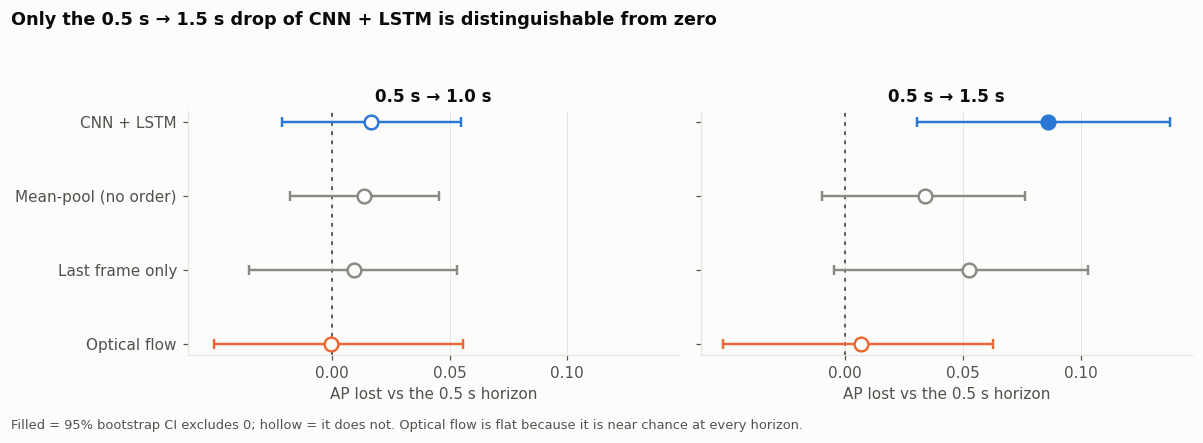

In [6]:
DEGRADE = ["lstm", "mean_pool", "last_frame", "optical_flow"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharex=True, sharey=True)
y_positions = np.arange(len(DEGRADE))[::-1]

for ax, far in zip(axes, [1.0, 1.5]):
    ax.axvline(0, color=INK_2, linestyle=(0, (2, 3)), linewidth=1.2, zorder=1)
    for y, variant in zip(y_positions, DEGRADE):
        row = boot_row(f"AP drop 0.5s→{far}s: ", BOOT_NAME[variant], far)
        colour = BLUE if variant == "lstm" else ORANGE if variant == "optical_flow" else NEUTRAL
        ax.errorbar(row["estimate"], y, xerr=[[row["estimate"] - row["ci_low"]], [row["ci_high"] - row["estimate"]]],
                    fmt="o", markersize=9, color=colour, markerfacecolor=colour if row["excludes_zero"] else SURFACE,
                    markeredgewidth=1.6, capsize=3, elinewidth=1.6, zorder=3)
    ax.set_xticks([0.0, 0.05, 0.10])
    ax.set_title(f"0.5 s → {far} s")
    ax.set_xlabel("AP lost vs the 0.5 s horizon")
    ax.set_yticks(y_positions)
    ax.set_yticklabels([DISPLAY[v] for v in DEGRADE])
    ax.grid(axis="y", visible=False)

fig.suptitle("Only the 0.5 s → 1.5 s drop of CNN + LSTM is distinguishable from zero",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.text(0.01, 0.005, "Filled = 95% bootstrap CI excludes 0; hollow = it does not. Optical flow is flat because it is near chance at every horizon.",
         fontsize=8.5, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.92))
fig.savefig(FIGURE_DIR / "final_fig4_degradation.png", dpi=170)
plt.show()

## 6. Final results tables

**Table 1 — the three required models** (mean ± std over 5 seeds). Precision, Recall and F1 use a fixed 0.5 threshold; AP, ROC-AUC and recall at fixed false-alarm
rate do not depend on a threshold. For the naive model, recall at a fixed false-alarm rate is the chance value.

In [7]:
METRICS = [("AP", "AP"), ("ROC_AUC", "ROC-AUC"), ("Recall@FPR10", "Recall @ FPR≤10%"), ("Recall@FPR20", "Recall @ FPR≤20%"),
           ("Precision", "Precision"), ("Recall", "Recall"), ("F1", "F1")]


def fmt(variant, tte, column):
    mean, std = stat(variant, tte, column)
    return f"{mean:.3f}" if np.isnan(std) else f"{mean:.3f} ± {std:.3f}"


def build_table(variants):
    rows = []
    for tte in TTE_VALUES:
        for variant in variants:
            rows.append({"Model": DISPLAY[variant], "TTE (s)": tte, **{label: fmt(variant, tte, col) for col, label in METRICS}})
    return pd.DataFrame(rows)


main_table = build_table(["naive", "optical_flow", "lstm"])
main_table.to_csv(RESULTS_DIR / "final_results_table.csv", index=False)
print(main_table.to_string(index=False))

       Model  TTE (s)            AP       ROC-AUC Recall @ FPR≤10% Recall @ FPR≤20%     Precision        Recall            F1
       Naive      0.5         0.500         0.500            0.100            0.200         0.500         1.000         0.667
Optical flow      0.5         0.575         0.589            0.173            0.260         0.547         0.467         0.504
  CNN + LSTM      0.5 0.762 ± 0.019 0.750 ± 0.013    0.383 ± 0.034    0.547 ± 0.050 0.667 ± 0.018 0.735 ± 0.034 0.699 ± 0.009
       Naive      1.0         0.500         0.500            0.100            0.200         0.500         1.000         0.667
Optical flow      1.0         0.576         0.592            0.153            0.267         0.534         0.473         0.502
  CNN + LSTM      1.0 0.749 ± 0.011 0.726 ± 0.013    0.425 ± 0.015    0.511 ± 0.045 0.664 ± 0.035 0.633 ± 0.065 0.646 ± 0.027
       Naive      1.5         0.500         0.500            0.100            0.200         0.500         1.000       

**Table 2 — temporal ablation** (same format).

In [8]:
ablation_table = build_table(["optical_flow", "last_frame", "mean_pool", "lstm_train_shuffled", "lstm_test_shuffled", "lstm"])
ablation_table.to_csv(RESULTS_DIR / "final_ablation_table.csv", index=False)
print(ablation_table[["Model", "TTE (s)", "AP", "ROC-AUC", "Recall @ FPR≤10%"]].to_string(index=False))

                      Model  TTE (s)            AP       ROC-AUC Recall @ FPR≤10%
               Optical flow      0.5         0.575         0.589            0.173
            Last frame only      0.5 0.759 ± 0.005 0.750 ± 0.005    0.363 ± 0.024
       Mean-pool (no order)      0.5 0.737 ± 0.007 0.713 ± 0.005    0.425 ± 0.018
LSTM, shuffled train + test      0.5 0.736 ± 0.012 0.717 ± 0.007    0.387 ± 0.026
LSTM, shuffled at test only      0.5 0.728 ± 0.013 0.707 ± 0.009    0.367 ± 0.046
                 CNN + LSTM      0.5 0.762 ± 0.019 0.750 ± 0.013    0.383 ± 0.034
               Optical flow      1.0         0.576         0.592            0.153
            Last frame only      1.0 0.752 ± 0.007 0.729 ± 0.006    0.404 ± 0.027
       Mean-pool (no order)      1.0 0.725 ± 0.008 0.698 ± 0.007    0.360 ± 0.033
LSTM, shuffled train + test      1.0 0.719 ± 0.017 0.699 ± 0.012    0.360 ± 0.038
LSTM, shuffled at test only      1.0 0.725 ± 0.014 0.695 ± 0.017    0.377 ± 0.038
                

## 7. Why the Notebook 5 numbers should not be used

Notebook 5 kept the epoch with the best score on the evaluation videos and then reported that score. The `oracle_val_AP`
column of the summary reproduces that protocol. The gap to the clean protocol is the selection optimism.

In [9]:
rows = []
for tte in TTE_VALUES:
    clean = stat("lstm", tte, "AP")[0]
    oracle = summary[(summary["variant"] == "lstm") & (summary["tte"] == tte)]["oracle_val_AP_mean"].iloc[0]
    rows.append({"TTE (s)": tte, "Notebook 5 as reported": [0.7934, 0.7737, 0.7392][TTE_VALUES.index(tte)],
                 "Same protocol, 5-seed mean (oracle epoch)": round(oracle, 3),
                 "Clean protocol (epoch chosen on training videos)": round(clean, 3),
                 "Optimism": round(oracle - clean, 3)})
optimism_table = pd.DataFrame(rows)
optimism_table.to_csv(RESULTS_DIR / "final_selection_optimism.csv", index=False)
print(optimism_table.to_string(index=False))

 TTE (s)  Notebook 5 as reported  Same protocol, 5-seed mean (oracle epoch)  Clean protocol (epoch chosen on training videos)  Optimism
     0.5                  0.7934                                      0.790                                             0.762     0.028
     1.0                  0.7737                                      0.771                                             0.749     0.022
     1.5                  0.7392                                      0.734                                             0.675     0.059


## 8. Numbers behind the hypothesis check

In [10]:
print("AP of CNN + LSTM minus optical flow (paired bootstrap, 95% CI):")
for tte in TTE_VALUES:
    r = boot_row("AP diff: CNN+LSTM − ", "Optical flow", tte)
    print(f"  TTE {tte}: {r['estimate']:+.3f}  [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]")

print("\nAP lost relative to 0.5 s (paired bootstrap, 95% CI):")
for variant in ["lstm", "optical_flow", "last_frame", "mean_pool"]:
    for far in (1.0, 1.5):
        r = boot_row(f"AP drop 0.5s→{far}s: ", BOOT_NAME[variant], far)
        print(f"  {DISPLAY[variant]:<22s} 0.5→{far}: {r['estimate']:+.3f}  [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]")

AP of CNN + LSTM minus optical flow (paired bootstrap, 95% CI):
  TTE 0.5: +0.197  [+0.111, +0.266]
  TTE 1.0: +0.180  [+0.103, +0.251]
  TTE 1.5: +0.117  [+0.032, +0.192]

AP lost relative to 0.5 s (paired bootstrap, 95% CI):
  CNN + LSTM             0.5→1.0: +0.016  [-0.021, +0.055]
  CNN + LSTM             0.5→1.5: +0.086  [+0.030, +0.138]
  Optical flow           0.5→1.0: -0.000  [-0.050, +0.056]
  Optical flow           0.5→1.5: +0.007  [-0.052, +0.063]
  Last frame only        0.5→1.0: +0.010  [-0.035, +0.053]
  Last frame only        0.5→1.5: +0.052  [-0.005, +0.103]
  Mean-pool (no order)   0.5→1.0: +0.014  [-0.018, +0.045]
  Mean-pool (no order)   0.5→1.5: +0.034  [-0.010, +0.076]


## 9. Conclusions

Answers to the proposal's research question, from the 10-epoch, 5-seed results on the 300-video test set.

**RQ1 — How does performance change with time-to-event?**
CNN + LSTM scores AP 0.762 / 0.749 / 0.675 at 0.5 / 1.0 / 1.5 s. Performance is roughly stable between 0.5 s and 1.0 s and
falls at 1.5 s; only the 0.5 s → 1.5 s drop (0.086 AP, 95% CI 0.03–0.14) is distinguishable from zero. Even at 1.5 s the model is well
above chance (AP 0.5) and above optical flow.

**RQ2 — Does a learned model beat classical motion cues?**
Yes. CNN + LSTM exceeds optical flow by +0.197 / +0.180 / +0.117 AP, and every interval excludes zero. At a ≤10% false-alarm rate it
recovers roughly 30–43% of collisions versus 15–21% for optical flow (chance 10%).

**RQ3 — Is the learned model using temporal information?**
Not demonstrably. A classifier on the single last frame performs as well as the LSTM at 0.5 s and 1.0 s and better at 1.5 s;
averaging frames or training on shuffled frames also stays within noise of the LSTM. Shuffling frames at test time costs the trained LSTM a small
amount (about 0.02–0.03 AP at 0.5–1.0 s), so it uses some ordering, but a model that never sees order does as well. The advantage over
optical flow therefore comes mainly from the pretrained visual features.

**Hypothesis.** The proposal predicted that the learned model would degrade *more slowly* than the motion baseline.
**This is not supported.** The learned model degrades measurably between 0.5 s and 1.5 s, whereas optical flow is flat — but flat only because it is
close to chance at every horizon, so there is little to lose.

## Limitations

* 300 test videos: differences of about 0.03 AP are near the noise floor, and a single AP has a 95% interval of about ±0.07.
* One frozen backbone (ResNet-18), 16 frames over a 2 s window; the temporal conclusion applies to this setup.
* Hyper-parameters were not tuned. The scaled-flow choice was made after seeing test results (≈0.01 AP effect).
* **Dataset-structure confound.** Video ids perfectly separate the classes (collision ids ≤ 1039, normal ids ≥ 1040). The models never see the id, but the two
  blocks may differ in recording conditions, so part of the CNN-feature advantage may be static-appearance recognition rather than collision cues.
  Notebook 8 shows that a single frame taken 3+ s before the event already reaches AP ≈ 0.70, which fits this reading. The headline numbers are valid
  as measured, but should not be described as "predicting collisions" without this qualification.